<a href="https://colab.research.google.com/github/VrgiPramudya/computer-vision/blob/main/Jobsheet_06_Galih_Virgi_Pramudya_Visi_Komputer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Persiapan Lingkungan

In [ ]:
# === Persiapan 1: instalasi pustaka ===
!pip install -q transformers

# === Persiapan 2: impor, cek GPU, seed, konfigurasi ===
import os, time, random, json, zipfile, urllib.request, gc
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch, torchvision
import torchvision.transforms.functional as TF

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CEPAT = DEVICE == "cpu"
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Perangkat:", DEVICE, " | ", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU saja")

CFG = dict(
    N_TEST = 20 if CEPAT else 50,
    N_TRAIN = 60 if CEPAT else 120,
    EPOCHS = 1 if CEPAT else 6,
    MIN_SIZE = 320 if CEPAT else 512,
    MAX_SIZE = 544 if CEPAT else 853,
    N_SAM = 6 if CEPAT else 20,
    N_PROYEK = 8 if CEPAT else 30,
)
print("Mode:", "CEPAT (CPU)" if CEPAT else "PENUH (GPU)", CFG)

FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
WAKTU = {}

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Perangkat: cuda  |  Tesla T4
Mode: PENUH (GPU) {'N_TEST': 50, 'N_TRAIN': 120, 'EPOCHS': 6, 'MIN_SIZE': 512, 'MAX_SIZE': 853, 'N_SAM': 20, 'N_PROYEK': 30}


#D1: Mengenal Data Segmentasi Instans (Penn-Fudan)

Jumlah citra: 170 | waktu 6.7 s
Total pejalan kaki berlabel: 423 | rata-rata per citra: 2.49 maks: 8
x: (3, 344, 374) | boxes: (1, 4) | masks: (1, 344, 374)


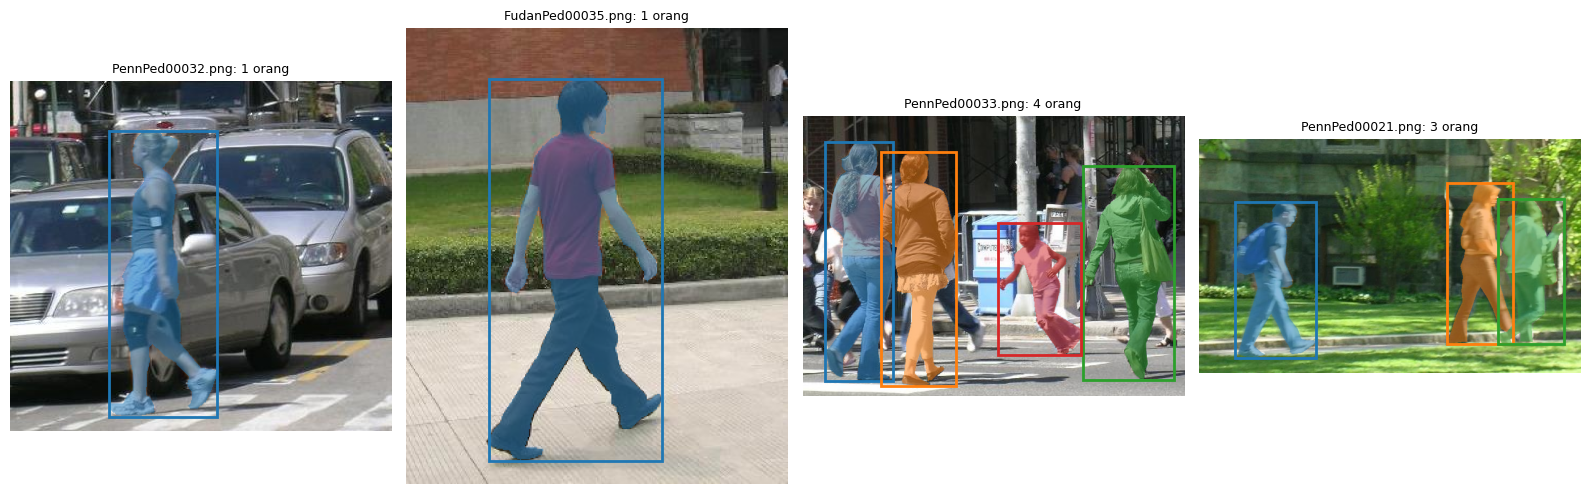

In [ ]:
# === D1.1 Unduh dan ekstrak Penn-Fudan ===
t0 = time.time()
os.makedirs("data", exist_ok=True)
if not os.path.isdir("data/PennFudanPed"):
    urllib.request.urlretrieve("https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip", "data/PennFudanPed.zip")
    with zipfile.ZipFile("data/PennFudanPed.zip") as z:
        z.extractall("data")

PF = "data/PennFudanPed"
NAMA = sorted(os.listdir(f"{PF}/PNGImages"))
print("Jumlah citra:", len(NAMA), "| waktu %.1f s" % (time.time() - t0))

# === D1.2 Dataset instans: boxes, labels, masks per orang ===
class PennFudan(torch.utils.data.Dataset):
    def __init__(self, nama, augment=False):
        self.nama, self.augment = nama, augment

    def __len__(self):
        return len(self.nama)

    def muat(self, i):
        n = self.nama[i]
        img = Image.open(f"{PF}/PNGImages/{n}").convert("RGB")
        m = np.array(Image.open(f"{PF}/PedMasks/{n[:-4]}_mask.png"))
        ids = np.unique(m)
        ids = ids[ids != 0] # buang latar (0)
        masks = (m[None] == ids[:, None, None]) # bool, satu per orang (N,H,W)
        return img, masks

    def __getitem__(self, i):
        img, masks = self.muat(i)
        x = TF.to_tensor(img)
        masks = torch.from_numpy(masks).to(torch.uint8)

        if self.augment and random.random() < 0.5:
            x, masks = x.flip(-1), masks.flip(-1)

        boxes = []
        for mk in masks:
            ys, xs = torch.where(mk > 0)
            boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])

        target = {
            "boxes": torch.tensor(boxes, dtype=torch.float32),
            "labels": torch.ones(len(masks), dtype=torch.int64), # 1 = pejalan kaki
            "masks": masks
        }
        return x, target

rng = random.Random(0); acak = NAMA[:] ; rng.shuffle(acak)
NAMA_TEST, NAMA_TRAIN = acak[:CFG["N_TEST"]], acak[50:50 + CFG["N_TRAIN"]]

ds_all = PennFudan(NAMA)
jml = [len(ds_all.muat(i)[1]) for i in range(len(NAMA))]
print("Total pejalan kaki berlabel:", sum(jml), "| rata-rata per citra: %.2f maks: %d" % (np.mean(jml), max(jml)))

ds_train = PennFudan(NAMA_TRAIN, augment=True)
ds_test = PennFudan(NAMA_TEST)
x, t = ds_test[0]
print("x:", tuple(x.shape), "| boxes:", tuple(t["boxes"].shape), "| masks:", tuple(t["masks"].shape))

# === D1.3 Visualisasi masker instans ===
WARNA = plt.cm.tab10(np.arange(10))[:, :3]

def overlay(img, masks, boxes=None, alpha=0.5, judul=None, ax=None):
    arr = np.array(img).astype(float) / 255
    for k, mk in enumerate(masks):
        mk = np.asarray(mk).astype(bool)
        arr[mk] = (1 - alpha) * arr[mk] + alpha * WARNA[k % 10]
    ax.imshow(arr)
    if boxes is not None:
        for k, b in enumerate(boxes):
            b = [float(v) for v in b]
            ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color=WARNA[k % 10], lw=2))
    if judul: ax.set_title(judul, fontsize=9)
    ax.axis("off")

fig, ax = plt.subplots(1, 4, figsize=(16,5))
for j in range(4):
    img, masks = ds_test.muat(j); t = ds_test[j][1]
    overlay(img, masks, t["boxes"], judul=f"{NAMA_TEST[j]}: {len(masks)} orang", ax=ax[j])

plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_dl_contoh_instans.png", dpi=110); plt.show()

#D3: Fine-Tuning Ringan Mask R-CNN

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:00<00:00, 183MB/s]


Parameter dilatih: 20.47 juta dari 43.92 juta
epoch 1 iterasi   0 loss total 2.387 mask 1.320 (4 s)
epoch 1 iterasi  10 loss total 0.306 mask 0.157 (7 s)
epoch 1 iterasi  20 loss total 0.466 mask 0.190 (10 s)
epoch 1 iterasi  30 loss total 0.366 mask 0.173 (12 s)
epoch 1 iterasi  40 loss total 0.291 mask 0.172 (16 s)
epoch 1 iterasi  50 loss total 0.317 mask 0.162 (19 s)
epoch 2 iterasi   0 loss total 0.173 mask 0.113 (21 s)
epoch 2 iterasi  10 loss total 0.413 mask 0.191 (24 s)
epoch 2 iterasi  20 loss total 0.244 mask 0.133 (27 s)
epoch 2 iterasi  30 loss total 0.289 mask 0.141 (30 s)
epoch 2 iterasi  40 loss total 0.170 mask 0.129 (33 s)
epoch 2 iterasi  50 loss total 0.272 mask 0.141 (36 s)
epoch 3 iterasi   0 loss total 0.202 mask 0.137 (40 s)
epoch 3 iterasi  10 loss total 0.182 mask 0.117 (43 s)
epoch 3 iterasi  20 loss total 0.144 mask 0.104 (46 s)
epoch 3 iterasi  30 loss total 0.284 mask 0.137 (49 s)
epoch 3 iterasi  40 loss total 0.227 mask 0.134 (52 s)
epoch 3 iterasi  50 l

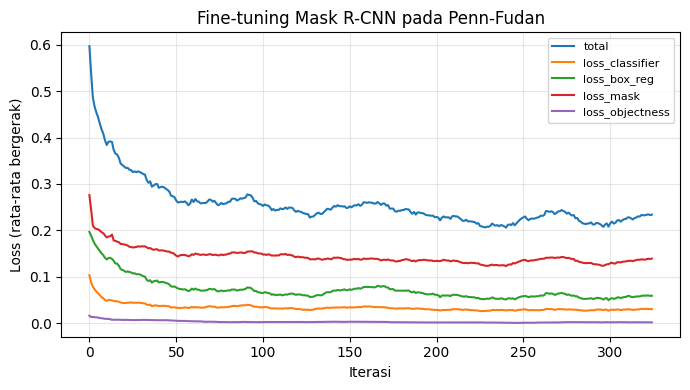

In [ ]:
# === D3.1 Siapkan model 2 kelas ===
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
W = MaskRCNN_ResNet50_FPN_Weights.DEFAULT

set_seed(42)
mrcnn_ft = maskrcnn_resnet50_fpn(weights=W, min_size=CFG["MIN_SIZE"], max_size=CFG["MAX_SIZE"])

in_feat = mrcnn_ft.roi_heads.box_predictor.cls_score.in_features
mrcnn_ft.roi_heads.box_predictor = FastRCNNPredictor(in_feat, 2)
mrcnn_ft.roi_heads.mask_predictor = MaskRCNNPredictor(256, 256, 2)

# bekukan ResNet-50
for p in mrcnn_ft.backbone.body.parameters():
    p.requires_grad = False

mrcnn_ft = mrcnn_ft.to(DEVICE)
dilatih = [p for p in mrcnn_ft.parameters() if p.requires_grad]
print("Parameter dilatih: %.2f juta dari %.2f juta" % (sum(p.numel() for p in dilatih) / 1e6, sum(p.numel() for p in mrcnn_ft.parameters()) / 1e6))

# === D3.2 Loop pelatihan ===
collate = lambda b: tuple(zip(*b))
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=2, shuffle=True, collate_fn=collate)
opt = torch.optim.SGD(dilatih, lr=0.005, momentum=0.9, weight_decay=5e-4)

riwayat = []; t0 = time.time()
for ep in range(CFG["EPOCHS"]):
    mrcnn_ft.train()
    for it, (xs, ts) in enumerate(dl_train):
        xs = [x.to(DEVICE) for x in xs]
        ts = [{k: v.to(DEVICE) for k, v in t.items()} for t in ts]
        losses = mrcnn_ft(xs, ts)
        loss = sum(losses.values())

        opt.zero_grad(); loss.backward(); opt.step()
        riwayat.append({k: v.item() for k, v in losses.items()} | {"total": loss.item()})

        if it % 10 == 0:
            print(f"epoch {ep+1} iterasi {it:3d} loss total {loss.item():.3f} mask {losses['loss_mask'].item():.3f} ({time.time()-t0:.0f} s)")

WAKTU["Fine-tuning Mask R-CNN"] = time.time() - t0
print("Waktu fine-tuning: %.1f s untuk %d iterasi" % (WAKTU["Fine-tuning Mask R-CNN"], len(riwayat)))

# === D3.3 Kurva loss fine-tuning ===
plt.figure(figsize=(7, 4))
for k in ["total", "loss_classifier", "loss_box_reg", "loss_mask", "loss_objectness"]:
    v = np.array([r[k] for r in riwayat]); w = max(1, len(v) // 10)
    plt.plot(np.convolve(v, np.ones(w) / w, mode="valid"), label=k)

plt.xlabel("Iterasi"); plt.ylabel("Loss (rata-rata bergerak)")
plt.title("Fine-tuning Mask R-CNN pada Penn-Fudan")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d3_kurva_finetune.png", dpi=120); plt.show()

#D4: Evaluasi Masker dengan IoU dan AP

{'AP50': 0.9657, 'AP75': 0.898, 'AP[.50:.95]': 0.7162, 'mIoU_cocok@0.5': 0.8583, 'Recall@0.5': 1.0, 'jumlah_GT': 126}  | 8.8 s
Mask R-CNN COCO (tanpa latih)       {'AP50': 0.9657, 'AP75': 0.898, 'AP[.50:.95]': 0.7162, 'mIoU_cocok@0.5': 0.8583, 'Recall@0.5': 1.0, 'jumlah_GT': 126}
Mask R-CNN fine-tuned Penn-Fudan    {'AP50': 0.9876, 'AP75': 0.963, 'AP[.50:.95]': 0.7674, 'mIoU_cocok@0.5': 0.8725, 'Recall@0.5': 1.0, 'jumlah_GT': 126}


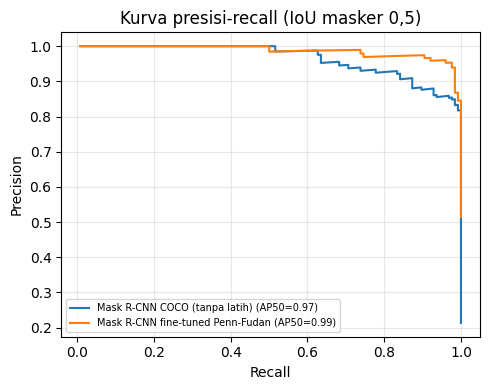

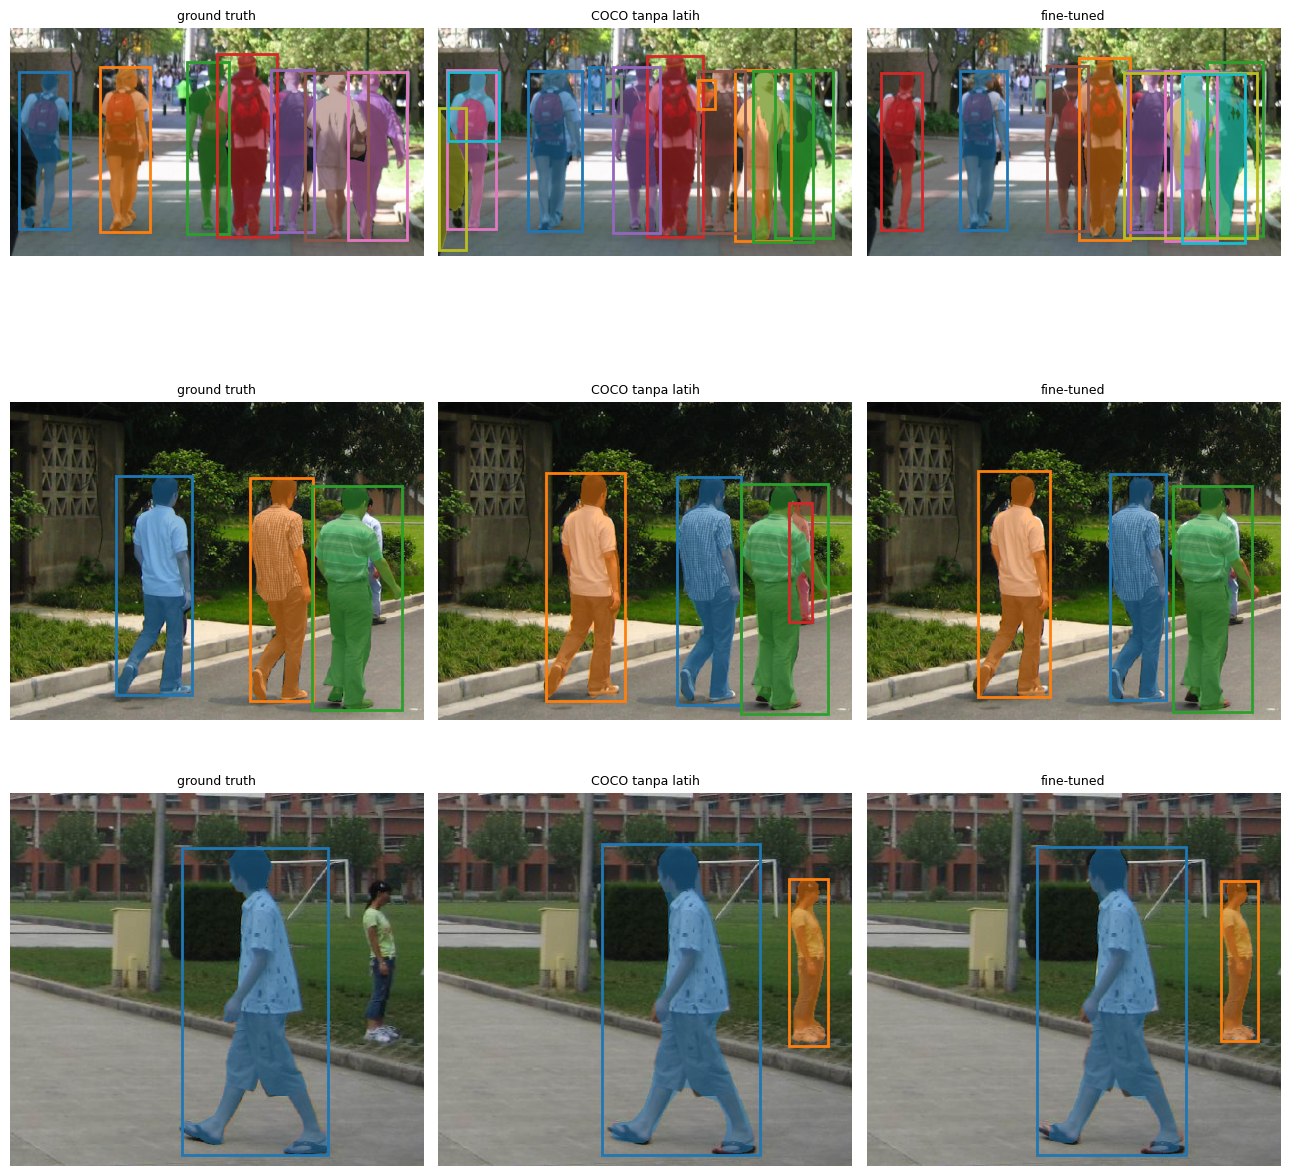

In [ ]:
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights

W = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
# Muat ulang model COCO pra-latih yang dibutuhkan sebagai pembanding
mrcnn_coco = maskrcnn_resnet50_fpn(weights=W, min_size=CFG["MIN_SIZE"], max_size=CFG["MAX_SIZE"]).to(DEVICE).eval()

# Definisikan ulang fungsi deteksi
@torch.no_grad()
def deteksi(model, x, label_orang=1, skor_min=0.5):
    out = model([x.to(DEVICE)])[0]
    keep = (out["labels"] == label_orang) & (out["scores"] >= skor_min)
    return {k: v[keep].cpu() for k, v in out.items()}
# ===============================================================

# === D4.1 Evaluator mask: IoU, AP50, AP[.50:.95] ===
def iou_mask(a, b):
    a = a.reshape(len(a), -1).float(); b = b.reshape(len(b), -1).float()
    inter = a @ b.T
    return inter / (a.sum(1, keepdim=True) + b.sum(1)[None] - inter).clamp_min(1)

def average_precision(skor, tp, npos):
    if len(skor) == 0: return 0.0, np.array([0.]), np.array([0.])
    o = np.argsort(-np.array(skor)); tp = np.array(tp)[o]
    ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
    rec = ctp / max(npos, 1); prec = ctp / np.maximum(ctp + cfp, 1e-9)
    mrec = np.r_[0, rec, 1]; mpre = np.r_[0, prec, 0]
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    i = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[i+1] - mrec[i]) * mpre[i + 1])), rec, prec

@torch.no_grad()
def evaluasi_instans(model, ds, label_orang=1, skor_min=0.05):
    model.eval(); semua = []
    for i in range(len(ds)):
        x, t = ds[i]
        o = deteksi(model, x, label_orang, skor_min)
        P = o["masks"][:, 0] > 0.5; G = t["masks"].bool()
        semua.append((o["scores"].numpy(), iou_mask(P, G) if len(P) else torch.zeros(0, len(G)), len(G)))

    npos = sum(s[2] for s in semua); hasil = {}
    for thr in np.arange(0.5, 0.96, 0.05):
        skor, tp, iou_cocok = [], [], []
        for sc, M, g in semua:
            pakai = set()
            for p in np.argsort(-sc):
                skor.append(sc[p]); best, bj = 0, -1
                for j in range(g):
                    if j not in pakai and M[p, j] > best:
                        best, bj = M[p, j].item(), j
                if best >= thr:
                    pakai.add(bj); tp.append(1); iou_cocok.append(best)
                else:
                    tp.append(0)
        ap, rec, prec = average_precision(skor, tp, npos)
        hasil[round(float(thr), 2)] = (ap, rec, prec, iou_cocok)

    return {"AP50": hasil[0.5][0], "AP75": hasil[0.75][0],
            "AP[.50:.95]": float(np.mean([v[0] for v in hasil.values()])),
            "mIoU_cocok@0.5": float(np.mean(hasil[0.5][3])) if hasil[0.5][3] else 0.0,
            "Recall@0.5": float(hasil[0.5][1][-1]), "jumlah_GT": npos,
            "_pr": hasil[0.5][1:3]}

t0 = time.time()
HASIL = {"Mask R-CNN COCO (tanpa latih)": evaluasi_instans(mrcnn_coco, ds_test)}
WAKTU["Evaluasi COCO zero-shot"] = time.time() - t0

ringkas = lambda m: {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m.items() if not k.startswith("_")}
print(ringkas(HASIL["Mask R-CNN COCO (tanpa latih)"]), " | %.1f s" % WAKTU["Evaluasi COCO zero-shot"])

# === D4.2 Evaluasi model hasil fine-tuning dan bandingkan ===
t0 = time.time()
HASIL["Mask R-CNN fine-tuned Penn-Fudan"] = evaluasi_instans(mrcnn_ft, ds_test)
WAKTU["Evaluasi fine-tuned"] = time.time() - t0

for k, v in HASIL.items():
    print(f"{k:35s}", ringkas(v))

plt.figure(figsize=(5, 4))
for k, v in HASIL.items():
    rec, prec = v["_pr"]
    plt.plot(rec, prec, label=f"{k} (AP50={v['AP50']:.2f})")

plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Kurva presisi-recall (IoU masker 0,5)")
plt.legend(fontsize=7); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d4_kurva_pr.png", dpi=120); plt.show()

# === D4.3 Visual: GT vs COCO vs fine-tuned ===
fig, ax = plt.subplots(3, 3, figsize=(13, 13))
for r, j in enumerate([4, 5, 6]):
    x, t = ds_test[j]; img, gm = ds_test.muat(j)

    # Ground truth
    overlay(img, gm, t["boxes"], judul="ground truth", ax=ax[r, 0])

    # Model COCO tanpa latih
    o = deteksi(mrcnn_coco, x)
    overlay(img, (o["masks"][:, 0] > 0.5).numpy(), o["boxes"], judul="COCO tanpa latih", ax=ax[r, 1])

    # Model fine-tuned
    o = deteksi(mrcnn_ft, x)
    overlay(img, (o["masks"][:, 0] > 0.5).numpy(), o["boxes"], judul="fine-tuned", ax=ax[r, 2])

plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d4_perbandingan.png", dpi=100); plt.show()

#D5: Segment Anything (SAM) dengan Prompt Titik dan Kotak

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Parameter SAM ViT-B: 93.7 juta | waktu muat 14.2 s
1 titik per orang                   | IoU rata-rata 0.4141 (n = 52 orang)
3 titik per orang                   | IoU rata-rata 0.7715 (n = 52 orang)
kotak GT                            | IoU rata-rata 0.8994 (n = 52 orang)
kotak Mask R-CNN                    | IoU rata-rata 0.8953 (n = 52 orang)
masker Mask R-CNN (pembanding)      | IoU rata-rata 0.8742 (n = 52 orang)
Waktu: 16.4 s untuk 20 citra


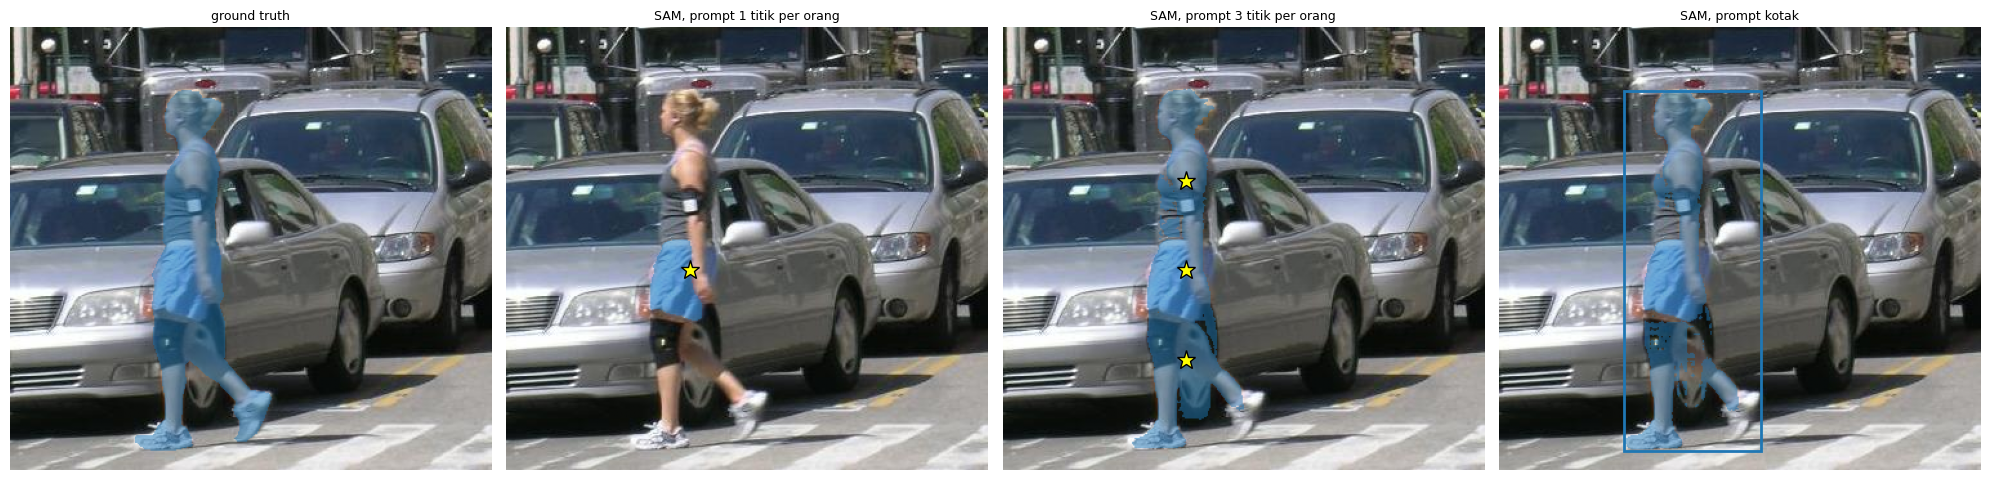

In [ ]:
# === D5.1 Muat SAM ===
del mrcnn_ft; gc.collect()
from transformers import SamModel, SamProcessor
import transformers; transformers.logging.set_verbosity_error()

t0 = time.time()
sam_proc = SamProcessor.from_pretrained("facebook/sam-vit-base")
sam = SamModel.from_pretrained("facebook/sam-vit-base").to(DEVICE).eval()
print("Parameter SAM ViT-B: %.1f juta | waktu muat %.1f s" % (sum(p.numel() for p in sam.parameters()) / 1e6, time.time() - t0))

@torch.no_grad()
def sam_embedding(img):
    inp = sam_proc(img, return_tensors="pt").to(DEVICE)
    return sam.get_image_embeddings(inp["pixel_values"])

@torch.no_grad()
def sam_segmentasi(img, points=None, boxes=None, multimask=False, emb=None):
    kw = {}
    if points is not None:
        kw["input_points"] = [points]; kw["input_labels"] = [[[1] * len(p) for p in points]]
    if boxes is not None:
        kw["input_boxes"] = [[list(map(float, b)) for b in boxes]]

    inp = sam_proc(img, return_tensors="pt", **kw).to(DEVICE)
    if emb is None:
        emb = sam.get_image_embeddings(inp["pixel_values"])
    inp.pop("pixel_values")

    out = sam(image_embeddings=emb, **inp, multimask_output=multimask)
    masks = sam_proc.image_processor.post_process_masks(out.pred_masks.cpu(), inp["original_sizes"].cpu(), inp["reshaped_input_sizes"].cpu())[0]

    skor = out.iou_scores[0].cpu()
    terbaik = skor.argmax(1)
    return masks[torch.arange(len(masks)), terbaik].bool(), skor.max(1).values

def titik_dalam(mk, fraksi=(0.5,)):
    ys, xs = np.where(mk); cx = xs.mean(); y0, y1 = ys.min(), ys.max()
    hasil = []
    for f in fraksi:
        cy = y0 + f * (y1 - y0)
        k = np.argmin((ys - cy)**2 + (xs - cx)**2)
        hasil.append([int(xs[k]), int(ys[k])])
    return hasil

# === D5.2 Eksperimen tiga jenis prompt ===
iou_prompt = {"1 titik per orang": [], "3 titik per orang": [], "kotak GT": [], "kotak Mask R-CNN": [], "masker Mask R-CNN (pembanding)": []}
contoh = None; t0 = time.time()

for j in range(CFG["N_SAM"]):
    x, t = ds_test[j]; img, gm = ds_test.muat(j); G = torch.from_numpy(gm)
    emb = sam_embedding(img)

    pts1 = [titik_dalam(mk) for mk in gm]
    pts3 = [titik_dalam(mk, (0.25, 0.5, 0.75)) for mk in gm]

    m_p1, _ = sam_segmentasi(img, points=pts1, multimask=True, emb=emb)
    m_p3, _ = sam_segmentasi(img, points=pts3, emb=emb)
    m_bx, _ = sam_segmentasi(img, boxes=t["boxes"].tolist(), emb=emb)

    iou_prompt["1 titik per orang"] += torch.diag(iou_mask(m_p1, G)).tolist()
    iou_prompt["3 titik per orang"] += torch.diag(iou_mask(m_p3, G)).tolist()
    iou_prompt["kotak GT"] += torch.diag(iou_mask(m_bx, G)).tolist()

    o = deteksi(mrcnn_coco, x)
    if len(o["boxes"]):
        m_det, _ = sam_segmentasi(img, boxes=o["boxes"].tolist(), emb=emb)
        iou_prompt["kotak Mask R-CNN"] += iou_mask(m_det, G).max(0).values.tolist()
        iou_prompt["masker Mask R-CNN (pembanding)"] += iou_mask(o["masks"][:, 0] > 0.5, G).max(0).values.tolist()
    else:
        iou_prompt["kotak Mask R-CNN"] += [0.0] * len(G)
        iou_prompt["masker Mask R-CNN (pembanding)"] += [0.0] * len(G)

    if j == 0:
        contoh = (img, gm, pts1, m_p1, pts3, m_p3, t["boxes"], m_bx)

WAKTU["SAM eksperimen"] = time.time() - t0
HASIL_SAM = {k: (float(np.mean(v)), len(v)) for k, v in iou_prompt.items()}
for k, (m, n) in HASIL_SAM.items():
    print(f"{k:35s} | IoU rata-rata {m:.4f} (n = {n} orang)")
print("Waktu: %.1f s untuk %d citra" % (WAKTU["SAM eksperimen"], CFG["N_SAM"]))

# === D5.3 Visualisasi prompt SAM ===
img, gm, pts1, m_p1, pts3, m_p3, bxs, m_bx = contoh
fig, ax = plt.subplots(1, 4, figsize=(20,5))

overlay(img, gm, judul="ground truth", ax=ax[0])
overlay(img, m_p1.numpy(), judul="SAM, prompt 1 titik per orang", ax=ax[1])
overlay(img, m_p3.numpy(), judul="SAM, prompt 3 titik per orang", ax=ax[2])

for a, P in ((ax[1], pts1), (ax[2], pts3)):
    for obj in P:
        for p in obj:
            a.plot(p[0], p[1], "*", color="yellow", ms=14, mec="k")

overlay(img, m_bx.numpy(), bxs, judul="SAM, prompt kotak", ax=ax[3])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d5_sam_prompt.png", dpi=110); plt.show()

#D6: Mini-Proyek Penghapus Latar Otomatis

Foto hewan: 30 ['Abyssinian_219', 'Abyssinian_37', 'Abyssinian_6', 'Abyssinian_85']
foto                         | skor det | IoU MaskRCNN |  IoU SAM
Abyssinian_219               |    0.997 |        0.990 |    0.993
Abyssinian_37                |    0.991 |        0.856 |    0.786
Abyssinian_6                 |    0.997 |        0.963 |    0.970
Abyssinian_85                |    0.996 |        0.996 |    0.998
Bengal_55                    |    0.968 |        0.999 |    1.000
Bombay_91                    |    0.994 |        0.940 |    0.973
British_Shorthair_64         |    0.997 |        0.999 |    1.000
Egyptian_Mau_6               |    0.997 |        0.998 |    0.999
Egyptian_Mau_62              |    0.998 |        0.963 |    0.958
Persian_4                    |    0.977 |        1.000 |    1.000
Siamese_25                   |     0.99 |        0.979 |    0.924
Siamese_63                   |    0.991 |        0.996 |    1.000
Sphynx_211                   |    0.975 |        0.557 |  

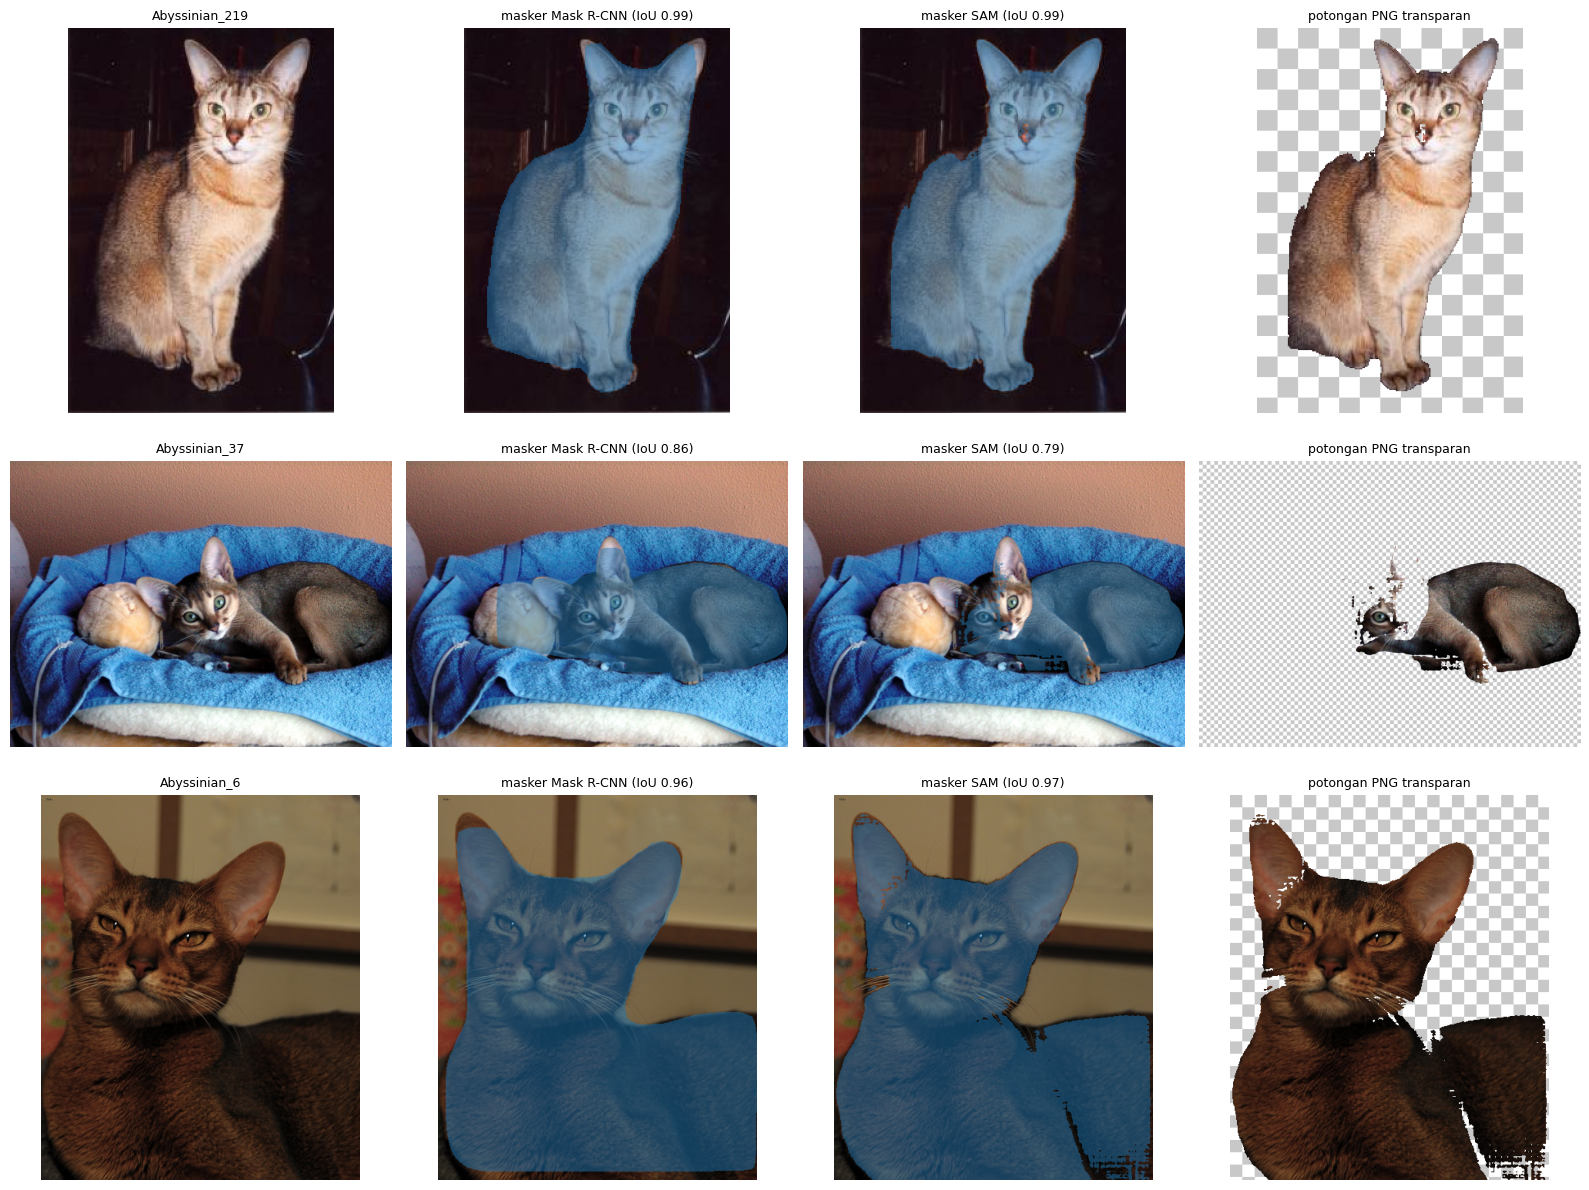

In [ ]:
# === D6.1 Ambil beberapa foto Oxford-IIIT Pet ===
import tarfile

def ambil_foto_pet(root="data/pet_subset", n=8):
    os.makedirs(f"{root}/images", exist_ok=True)
    os.makedirs(f"{root}/trimaps", exist_ok=True)
    ann = f"{root}/annotations.tar.gz"

    if not os.path.exists(ann):
        urllib.request.urlretrieve("https://thor.robots.ox.ac.uk/pets/annotations.tar.gz", ann)

    test_ids, trimaps = set(), {}
    with tarfile.open(ann, "r:gz") as t:
        for m in t:
            if m.name.endswith("annotations/test.txt"):
                test_ids = {l.split()[0] for l in t.extractfile(m).read().decode().splitlines() if l.strip()}
            elif "/trimaps/" in m.name and m.name.endswith(".png") and "._" not in m.name:
                trimaps[os.path.basename(m.name)[:-4]] = t.extractfile(m).read()

    ada = sorted(f[:-4] for f in os.listdir(f"{root}/images") if f[:-4] in test_ids)
    if len(ada) >= n: return ada[:n]

    with urllib.request.urlopen("https://thor.robots.ox.ac.uk/pets/images.tar.gz") as r, tarfile.open(fileobj=r, mode="r:gz") as t:
        for m in t:
            iid = os.path.basename(m.name)[:-4]
            if m.name.endswith(".jpg") and iid in test_ids and iid in trimaps and iid not in ada:
                open(f"{root}/images/{iid}.jpg", "wb").write(t.extractfile(m).read())
                open(f"{root}/trimaps/{iid}.png", "wb").write(trimaps[iid])
                ada.append(iid)
            if len(ada) >= n: break

    return sorted(ada)[:n]

PET = "data/pet_subset"
ID_PET = ambil_foto_pet(PET, CFG["N_PROYEK"])
print("Foto hewan:", len(ID_PET), ID_PET[:4])

# === TAMBAHAN MODIFIKASI DARI D2 (Untuk mengatasi NameError) ===
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights

W = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
KATEGORI = W.meta["categories"] # Mendefinisikan KATEGORI
# Memuat model mrcnn_coco yang dibutuhkan di fungsi potong_latar
mrcnn_coco = maskrcnn_resnet50_fpn(weights=W, min_size=CFG["MIN_SIZE"], max_size=CFG["MAX_SIZE"]).to(DEVICE).eval()
# ===============================================================

# === D6.2 Pipeline deteksi -> SAM -> potongan PNG transparan ===
LABEL_HEWAN = {KATEGORI.index("cat"), KATEGORI.index("dog")}
os.makedirs("hasil_potongan", exist_ok=True)

@torch.no_grad()
def potong_latar(path):
    img = Image.open(path).convert("RGB")
    out = mrcnn_coco([TF.to_tensor(img).to(DEVICE)])[0]
    pilih = [i for i, l in enumerate(out["labels"].tolist()) if l in LABEL_HEWAN]

    if not pilih:
        return img, None, None, None

    i = pilih[0]
    m_rcnn = (out["masks"][i, 0] > 0.5).cpu()
    m_sam, _ = sam_segmentasi(img, boxes=[out["boxes"][i].tolist()])
    return img, m_rcnn, m_sam[0], float(out["scores"][i])

def iou_trimap(m, tri):
    valid = tri != 3; g = tri == 1; m = m.numpy()
    return ((m & g) & valid).sum() / max(((m | g) & valid).sum(), 1)

t0 = time.time(); rekap = []; tampil = []
for iid in ID_PET:
    img, m_rcnn, m_sam, skor = potong_latar(f"{PET}/images/{iid}.jpg")
    tri = np.array(Image.open(f"{PET}/trimaps/{iid}.png"))

    if m_sam is None:
        rekap.append((iid, None, 0.0, 0.0)); continue

    rgba = np.dstack([np.array(img), (m_sam.numpy() * 255).astype(np.uint8)])
    Image.fromarray(rgba).save(f"hasil_potongan/{iid}.png")
    rekap.append((iid, skor, iou_trimap(m_rcnn, tri), iou_trimap(m_sam, tri)))
    tampil.append((img, m_rcnn, m_sam, rgba, rekap[-1]))

WAKTU["Mini-proyek"] = time.time() - t0
print(f"{'foto':28s} | {'skor det':>8s} | {'IoU MaskRCNN':>12s} | {'IoU SAM':>8s}")
for r in rekap:
    print(f"{r[0]:28s} | {r[1] if r[1] is None else round(r[1], 3)!s:>8s} | {r[2]:12.3f} | {r[3]:8.3f}")

iou_r = np.mean([r[2] for r in rekap]); iou_s = np.mean([r[3] for r in rekap])
print("Rata-rata IoU Mask R-CNN: %.4f | Mask R-CNN + SAM: %.4f | waktu %.1f s" % (iou_r, iou_s, WAKTU["Mini-proyek"]))

# === D6.3 Visualisasi hasil mini-proyek ===
n = min(3, len(tampil))
fig, ax = plt.subplots(n, 4, figsize=(16, 4*n), squeeze=False)
for r in range(n):
    img, m_rcnn, m_sam, rgba, rk = tampil[r]
    ax[r, 0].imshow(img); ax[r, 0].set_title(rk[0], fontsize=9)

    overlay(img, [m_rcnn.numpy()], judul=f"masker Mask R-CNN (IoU {rk[2]:.2f})", ax=ax[r, 1])
    overlay(img, [m_sam.numpy()], judul=f"masker SAM (IoU {rk[3]:.2f})", ax=ax[r, 2])

    yy, xx = np.indices(rgba.shape[:2])
    kotak = np.where((((yy // 16) + (xx // 16)) % 2 == 0)[..., None], 200, 255)
    a = rgba[..., 3:] / 255.0
    ax[r, 3].imshow((a * rgba[..., :3] + (1 - a) * kotak).astype(np.uint8))
    ax[r, 3].set_title("potongan PNG transparan", fontsize=9)

    for c in range(4): ax[r, c].axis("off")

plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d6_miniproyek.png", dpi=100); plt.show()

#Penugasan

Silakan unggah minimal 5 foto Anda (format .jpg atau .png):


Saving mobil6.jpg to mobil6.jpg
Saving mobil5.jpg to mobil5.jpg
Saving mobil4.jpg to mobil4.jpg
Saving mobil3.jpg to mobil3.jpg
Saving mobil2.jpg to mobil2.jpg


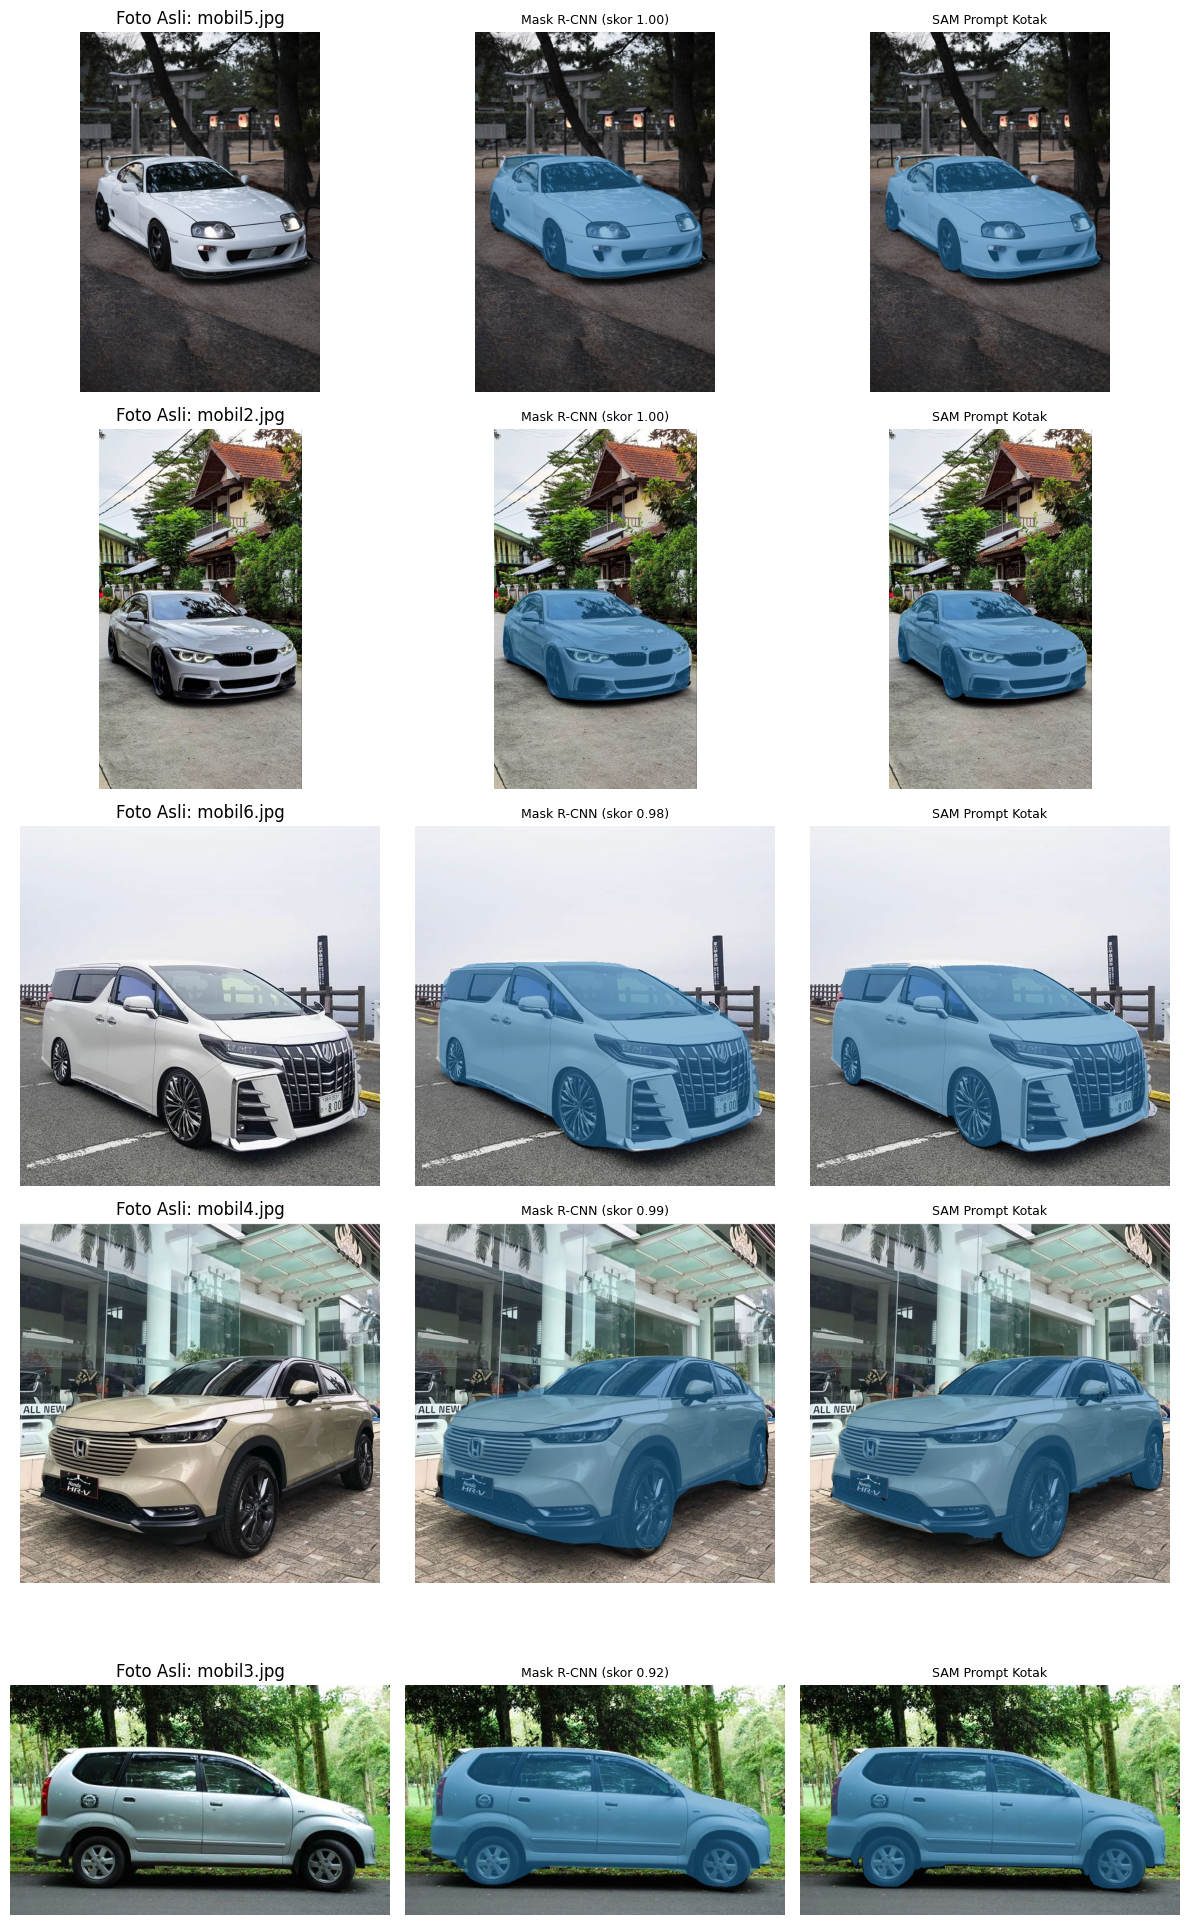

In [15]:
import os
from google.colab import files
from PIL import Image
import numpy as np
import torch
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt

# 1. GANTI KELAS INI SESUAI PROYEK ANDA (misal: "car", "apple", "bottle")
KELAS_TARGET = "car"
ID_TARGET = KATEGORI.index(KELAS_TARGET)

# 2. Buat folder dan unggah gambar
DIR_PROYEK = "data/proyek_ku"
os.makedirs(DIR_PROYEK, exist_ok=True)
print("Silakan unggah minimal 5 foto Anda (format .jpg atau .png):")
uploaded = files.upload()

for filename in uploaded.keys():
    os.rename(filename, os.path.join(DIR_PROYEK, filename))

foto_list = [f for f in os.listdir(DIR_PROYEK) if f.endswith(('.jpg', '.png'))]

# 3. Pipeline: Deteksi (Mask R-CNN) -> Segmentasi (SAM)
@torch.no_grad()
def potong_proyek_custom(path):
    img = Image.open(path).convert("RGB")
    out = mrcnn_coco([TF.to_tensor(img).to(DEVICE)])[0]

    # Cari objek sesuai kelas target
    pilih = [i for i, l in enumerate(out["labels"].tolist()) if l == ID_TARGET]

    if not pilih:
        return img, None, None, None

    i = pilih[0] # Ambil skor tertinggi
    m_rcnn = (out["masks"][i, 0] > 0.5).cpu()
    m_sam, _ = sam_segmentasi(img, boxes=[out["boxes"][i].tolist()])
    return img, m_rcnn, m_sam[0], float(out["scores"][i])

# 4. Visualisasi Hasil
fig, ax = plt.subplots(len(foto_list), 3, figsize=(12, 4 * len(foto_list)))
if len(foto_list) == 1: ax = [ax] # Penyesuaian jika cuma 1 foto

for r, fname in enumerate(foto_list):
    path = os.path.join(DIR_PROYEK, fname)
    img, m_rcnn, m_sam, skor = potong_proyek_custom(path)

    ax[r][0].imshow(img)
    ax[r][0].set_title(f"Foto Asli: {fname}")

    if m_sam is not None:
        overlay(img, [m_rcnn.numpy()], judul=f"Mask R-CNN (skor {skor:.2f})", ax=ax[r][1])
        overlay(img, [m_sam.numpy()], judul=f"SAM Prompt Kotak", ax=ax[r][2])
    else:
        ax[r][1].set_title(f"Tidak ditemukan '{KELAS_TARGET}'")
        ax[r][2].set_title("Gagal diproses SAM")

    for c in range(3): ax[r][c].axis("off")

plt.tight_layout(); plt.show()